## Long the strongest, short the weakest

Ten perpetuals at Binance, ranked each Monday by their return over the 30 days before:
long the three strongest and short the three weakest, a sixth of the account each, so the
book holds as much short as long. A perpetual pays or receives funding every eight hours,
on a short as on a long, and one margin wallet carries every leg. Daily bars, 2023 to 2025.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 2.0.0, exchange-router 3.0.1


### The bars and their funding

`funding=True` fetches every perpetual's funding events beside its bars, which
`binance_perp` charges at their real times.

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT", "SOLUSDT", "BNBUSDT", "XRPUSDT", "DOGEUSDT", "ADAUSDT",
           "AVAXUSDT", "LINKUSDT", "LTCUSDT"]

PATH = pathlib.Path("../bars/binance-linear-ten-1d-2023-2025")

if PATH.exists():
    data = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        data = probatum.Data.from_router(router, exchange="binance", market="linear",
                                         interval="1d", symbols=SYMBOLS,
                                         start="2023-01-01", end="2025-12-31", funding=True)
    data.save(path=PATH)

print(data, f"{len(data.funding):,} funding events")

Data(10 instruments, 1d, 1096 bars from 2023-01-01 00:00 to 2025-12-31 00:00) 32,880 funding events


### The weights

Each coin's 30-day return ranked across the ten. Only Mondays carry weights; the rows
between are NaN, which hold the positions as they are.

In [3]:
closes   = data.closes
momentum = closes / probatum.ta.shift(closes, bars=30) - 1.0
rank     = numpy.argsort(numpy.argsort(momentum, axis=1), axis=1)

monday = (pandas.to_datetime(data.time, utc=True).dayofweek == 0) & numpy.isfinite(
    momentum).all(axis=1)

weights = numpy.full(shape=closes.shape, fill_value=numpy.nan)
weights[monday] = numpy.where(rank[monday] >= 7, 1.0 / 6.0,
                              numpy.where(rank[monday] <= 2, -1.0 / 6.0, 0.0))

result = probatum.backtest(weights, data=data, venue="binance_perp")

result

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,-17.00,189.50,,,,,1
cagr_pct,-6.02,42.52,,,,,1
volatility_pct,24.95,73.19,,,,,1
sharpe,-0.12,0.85,-1.25,1.01,0.95,"delta method, Newey-West lag 3, floored at lag zero",
max_drawdown_pct,47.70,57.24,,,,,1
exposure_pct,96.71,,,,,,
num_trades,300,,,,,,
win_rate,0.42,,0.36,0.47,0.95,percentile bootstrap of round trips,
profit_factor,0.92,,0.60,1.39,0.95,BCa bootstrap of round trips,
costs,587,,,,,,


### Funding paid and received

Each round trip carries the funding charged while it was open. A long pays it when the rate
is positive and a short receives it, so the two sides split as below.

In [4]:
trades = result.trades.to_pandas()

sides = trades.groupby(by="side")[["pnl", "fees", "funding"]].sum()
sides.insert(loc=0, column="round trips", value=trades.groupby(by="side").size())

print(f"funding over the run {result.costs['funding']:,.2f} USDT, a negative sum received")

sides.round(decimals=2)

funding over the run -140.18 USDT, a negative sum received


,round trips,pnl,fees,funding
side,,,,
long,144,7203.95,222.06,911.02
short,162,-8904.32,254.61,-1051.20


### What the margin wallet carried

The ledger holds the account at every close: its long and short notional together and
netted, and the margin the cap asks of them, each over the equity.

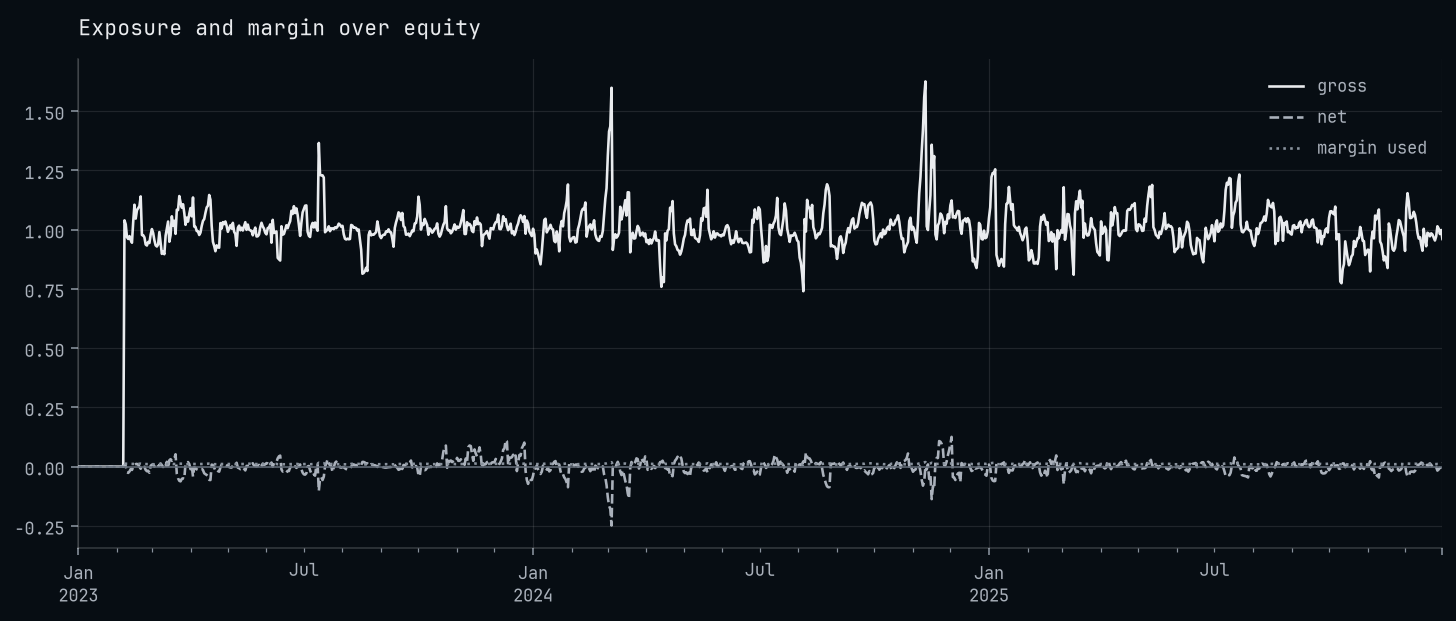

In [5]:
ledger = result.ledger.to_pandas().set_index(keys="time")

shares = pandas.DataFrame({"gross": ledger["gross_exposure"] / ledger["equity"],
                           "net": ledger["net_exposure"] / ledger["equity"],
                           "margin used": ledger["margin_used"] / ledger["equity"]})

axes = shares.plot(title="Exposure and margin over equity", xlabel="")
axes.axhline(y=0.0, color="C3", linewidth=0.8)
matplotlib.pyplot.show()

### Each coin

What each coin made in the account, and how often it was held on each side.

In [6]:
coins = trades.groupby(by=["instrument", "side"]).size().unstack(level="side", fill_value=0)
coins = coins.reindex(index=list(data.names))

coins["funding, USDT"] = trades.groupby(by="instrument")["funding"].sum()
coins["pnl, USDT"]     = [result[name].pnl[-1] for name in coins.index]

coins.round(decimals=2)

side,long,short,"funding, USDT","pnl, USDT"
instrument,,,,
BTCUSDT,23,8,82.06,796.19
ETHUSDT,12,13,89.20,575.59
SOLUSDT,16,18,100.83,27.20
BNBUSDT,19,15,-146.56,-766.55
XRPUSDT,12,19,-139.09,171.79
DOGEUSDT,12,17,-30.03,-1211.90
ADAUSDT,12,18,-3.44,-966.56
AVAXUSDT,8,18,39.78,1336.99
LINKUSDT,13,17,22.28,549.23


### One coin's round trips

A short's entry is drawn over its bar and a long's under it.

In [7]:
result.chart(probatum.chart.marks.Line(result["SOLUSDT"].weight, name="SOLUSDT's weight",
                                       panel="weight", step=True),
             instrument="SOLUSDT", focus=365,
             title="SOLUSDT of the ten, daily, binance perpetuals")

Chart(bars=1096, panels=4)